# SAP-DCG: Representative Synthetic Dataset Evaluation Metrics

This notebook computes and plots **representative metrics from every category** in [`docs/synthetic_evaluation_metrics_reference.md`](../docs/synthetic_evaluation_metrics_reference.md) and [`docs/ids_generative_metrics_summary-v2.xlsx`](../docs/ids_generative_metrics_summary-v2.xlsx), aligned with [`docs/statistics evaluation.txt`](../docs/statistics%20evaluation.txt) (**Reliability**, **Security**, **Balance**, and **Numerical Statistical Methods**).

### Evaluated Artifacts (Latest Runs)
- **CTGAN (`result_2`):** `results/ctgan/result_2/synthetic_samples_kept.csv` (`429` filtered synthetic attack flows), `unsw_nb15_final_pipeline_train.csv` (`690,657` rows), `pipeline_tuning_summary.json`
- **TVAE (`result_1`):** `results/tvae/result_1/unsw_nb15_final_pipeline_train.csv` (`690,228` rows; Round 1 chose `y_max=1`, so 0 synthetic rows were injected), `pipeline_tuning_summary.json` *(Note: `tvae/result_1/synthetic_samples_kept.csv` is byte-identical to `ctgan/result_2/synthetic_samples_kept.csv` and is flagged explicitly in this notebook.)*
- **Reference Real Splits:** `dataset/dev_splits/NF-UNSW-NB15-v3_train.csv`, `NF-UNSW-NB15-v3_test.csv`, `dataset/holdout_set/NF-UNSW-NB15-v3.csv`, and `dataset/synthetic_deficit.json`

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import jensenshannon
from scipy.stats import anderson_ksamp, chi2_contingency, ks_2samp, spearmanr, wasserstein_distance
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, precision_recall_fscore_support, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
SEED = 42
rng = np.random.default_rng(SEED)

# Resolve SAP-DCG root cleanly whether launched from notebooks/ or SAP-DCG/
cwd = Path(".").resolve()
ROOT = cwd.parent if cwd.name == "notebooks" else (cwd / "SAP-DCG" if (cwd / "SAP-DCG").exists() else cwd)
print("SAP-DCG Root:", ROOT)

CATEGORICAL_FEATURES = [
    "PROTOCOL", "L7_PROTO", "TCP_FLAGS", "CLIENT_TCP_FLAGS",
    "SERVER_TCP_FLAGS", "ICMP_TYPE", "ICMP_IPV4_TYPE",
    "DNS_QUERY_ID", "DNS_QUERY_TYPE", "DNS_TTL_ANSWER", "FTP_COMMAND_RET_CODE",
]
RARE_CLASSES = ["Analysis", "Backdoor", "Shellcode", "Worms"]

SAP-DCG Root: /run/media/thanh/Data/Project A/SAP-DCG


In [2]:
# Load real splits, synthetic outputs, and JSON summaries
train_df = pd.read_csv(ROOT / "dataset/dev_splits/NF-UNSW-NB15-v3_train.csv")
test_df = pd.read_csv(ROOT / "dataset/dev_splits/NF-UNSW-NB15-v3_test.csv")
holdout_df = pd.read_csv(ROOT / "dataset/holdout_set/NF-UNSW-NB15-v3.csv")

ctgan_syn = pd.read_csv(ROOT / "results/ctgan/result_2/synthetic_samples_kept.csv")
tvae_syn_file = pd.read_csv(ROOT / "results/tvae/result_1/synthetic_samples_kept.csv")
ctgan_final_train = pd.read_csv(ROOT / "results/ctgan/result_2/unsw_nb15_final_pipeline_train.csv", usecols=["Label", "Attack"])
tvae_final_train = pd.read_csv(ROOT / "results/tvae/result_1/unsw_nb15_final_pipeline_train.csv", usecols=["Label", "Attack"])

with open(ROOT / "dataset/synthetic_deficit.json") as f:
    deficit_cfg = json.load(f)
with open(ROOT / "results/ctgan/result_2/pipeline_tuning_summary.json") as f:
    ctgan_summary = json.load(f)
with open(ROOT / "results/tvae/result_1/pipeline_tuning_summary.json") as f:
    tvae_summary = json.load(f)

feature_cols = [c for c in train_df.columns if c not in ["Label", "Attack"]]
cat_cols = [c for c in CATEGORICAL_FEATURES if c in feature_cols]
cont_cols = [c for c in feature_cols if c not in cat_cols]

real_attacks = train_df[train_df["Label"] == 1].reset_index(drop=True)
holdout_attacks = holdout_df[holdout_df["Label"] == 1].reset_index(drop=True)

# Clean numeric matrices helper
def clean_numeric(df, cols, fill_series=None):
    out = df[cols].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    if fill_series is None:
        fill_series = out.median().fillna(0.0)
    return out.fillna(fill_series), fill_series

print(f"Real Train: {len(train_df):,} (Attacks: {len(real_attacks):,}) | Test: {len(test_df):,} | Holdout: {len(holdout_df):,}")
print(f"CTGAN Kept Syn: {len(ctgan_syn):,} | CTGAN Final Train: {len(ctgan_final_train):,}")
print(f"TVAE Final Train: {len(tvae_final_train):,} (0 pipeline synthetic rows added; y_max=1)")
print(f"Note: results/tvae/result_1/synthetic_samples_kept.csv equals CTGAN kept CSV? {ctgan_syn.equals(tvae_syn_file)}")

Real Train: 690,228 (Attacks: 55,612) | Test: 197,208 | Holdout: 246,511
CTGAN Kept Syn: 429 | CTGAN Final Train: 690,657
TVAE Final Train: 690,228 (0 pipeline synthetic rows added; y_max=1)
Note: results/tvae/result_1/synthetic_samples_kept.csv equals CTGAN kept CSV? True


## 1. Statistical Reliability — Classifier Two-Sample Test (C2ST / Detection AUC)
**Reference:** Lopez-Paz & Oquab (2017), *Revisiting Classifier Two-Sample Tests*, ICLR 2017 (`10.48550/arXiv.1610.06545`); Qian et al. (2023), *Synthcity*.  
**Interpretation:** Trains a 5-fold cross-validated classifier (`Real=0` vs. `Synthetic=1`) on the attack classes present in `ctgan_syn`. An AUC near `0.50` indicates statistical indistinguishability; an AUC near `1.00` indicates easily detectable synthetic artifacts.

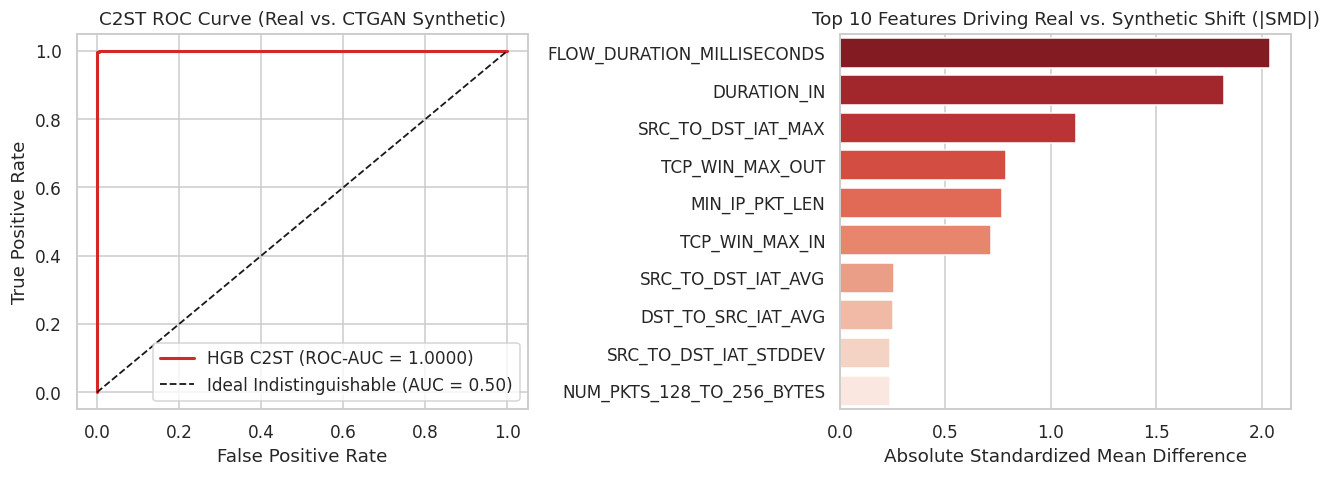

C2ST 5-Fold ROC-AUC: 1.0000 (Target: ~0.50; >0.80 indicates clear distinguishability)


In [3]:
# Metric 1: Classifier Two-Sample Test (C2ST)
covered_classes = sorted(ctgan_syn["Attack"].unique())
real_sub_pool = real_attacks[real_attacks["Attack"].isin(covered_classes)]
# Stratified match by class or balanced 429 vs 2,000 real attack sample
real_sample_c2st = real_sub_pool.sample(n=min(len(real_sub_pool), 4000), random_state=SEED)

X_real_c2, med_c2 = clean_numeric(real_sample_c2st, feature_cols)
X_syn_c2, _ = clean_numeric(ctgan_syn, feature_cols, med_c2)
X_c2 = pd.concat([X_real_c2, X_syn_c2], ignore_index=True)
y_c2 = np.r_[np.zeros(len(X_real_c2), dtype=int), np.ones(len(X_syn_c2), dtype=int)]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
clf_hgb = HistGradientBoostingClassifier(max_depth=5, max_iter=100, random_state=SEED)
probs_c2 = cross_val_predict(clf_hgb, X_c2, y_c2, cv=cv, method="predict_proba")[:, 1]
c2st_auc = roc_auc_score(y_c2, probs_c2)

# Fit once on full set to inspect top distinguishing features via absolute standardized mean shift
clf_hgb.fit(X_c2, y_c2)
fpr, tpr, _ = roc_curve(y_c2, probs_c2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, color="#d62728", lw=2, label=f"HGB C2ST (ROC-AUC = {c2st_auc:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1.2, label="Ideal Indistinguishable (AUC = 0.50)")
axes[0].set_title("C2ST ROC Curve (Real vs. CTGAN Synthetic)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")

# Compare Real vs Syn standardized mean difference across continuous features
mu_r = X_real_c2[cont_cols].mean()
sd_r = X_real_c2[cont_cols].std().replace(0, 1.0)
smd = ((X_syn_c2[cont_cols].mean() - mu_r).abs() / sd_r).sort_values(ascending=False).head(10)
sns.barplot(x=smd.values, y=smd.index, ax=axes[1], palette="Reds_r")
axes[1].set_title("Top 10 Features Driving Real vs. Synthetic Shift (|SMD|)")
axes[1].set_xlabel("Absolute Standardized Mean Difference")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()
print(f"C2ST 5-Fold ROC-AUC: {c2st_auc:.4f} (Target: ~0.50; >0.80 indicates clear distinguishability)")

## 2. Statistical Reliability — Anderson-Darling 2-Sample Test with BH-FDR ($q$-values)
**Reference:** Scholz & Stephens (1987), *K-Sample Anderson-Darling Tests*, JASA (`10.1080/01621459.1987.10478517`); Benjamini & Hochberg (1995), JRSS-B (`10.1111/j.2517-6161.1995.tb02031.x`).  
**Interpretation:** Tail-weighted CDF test across continuous NetFlow features, correcting $p$-values for multiple comparisons using Benjamini-Hochberg FDR. Features with $q$-val $> 0.05$ fail to reject distributional equality.

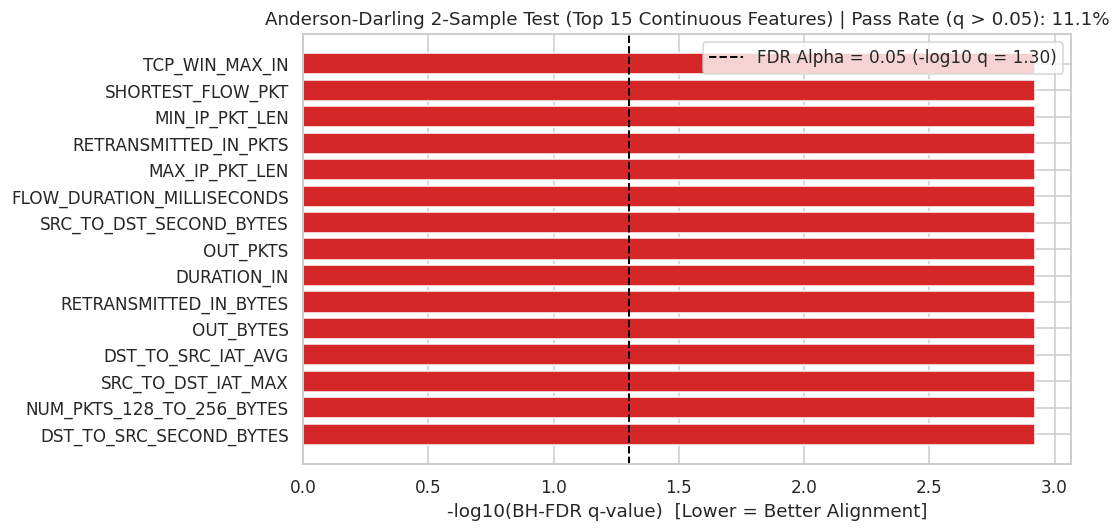

Tested 36 continuous features: 4/36 pass (q > 0.05). Median AD stat: 89.04


In [4]:
# Metric 2: Anderson-Darling 2-Sample Test + Benjamini-Hochberg FDR
real_ad_df, med_ad = clean_numeric(real_attacks[real_attacks["Attack"].isin(covered_classes)], cont_cols)
syn_ad_df, _ = clean_numeric(ctgan_syn, cont_cols, med_ad)

ad_rows = []
for col in cont_cols:
    r_vals = real_ad_df[col].values
    s_vals = syn_ad_df[col].values
    if np.std(r_vals) == 0 and np.std(s_vals) == 0:
        continue
    res = anderson_ksamp([r_vals, s_vals])
    p_val = float(np.clip(res.pvalue, 1e-12, 1.0))
    ad_rows.append({"feature": col, "ad_stat": float(res.statistic), "p_value": p_val})

ad_df = pd.DataFrame(ad_rows).sort_values("p_value").reset_index(drop=True)
m = len(ad_df)
ad_df["bh_q_value"] = np.minimum.accumulate((ad_df["p_value"] * m / (np.arange(1, m + 1)))[::-1])[::-1].clip(upper=1.0)
ad_df["neg_log10_q"] = -np.log10(ad_df["bh_q_value"].clip(lower=1e-12))

pass_rate_ad = (ad_df["bh_q_value"] > 0.05).mean()
top_ad = ad_df.sort_values("ad_stat", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#2ca02c" if q > 0.05 else "#d62728" for q in top_ad["bh_q_value"]]
ax.barh(top_ad["feature"][::-1], top_ad["neg_log10_q"][::-1], color=colors[::-1])
ax.axvline(-np.log10(0.05), color="black", linestyle="--", lw=1.3, label="FDR Alpha = 0.05 (-log10 q = 1.30)")
ax.set_title(f"Anderson-Darling 2-Sample Test (Top 15 Continuous Features) | Pass Rate (q > 0.05): {pass_rate_ad:.1%}")
ax.set_xlabel("-log10(BH-FDR q-value)  [Lower = Better Alignment]")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Tested {m} continuous features: {(ad_df['bh_q_value'] > 0.05).sum()}/{m} pass (q > 0.05). Median AD stat: {ad_df['ad_stat'].median():.2f}")

## 3. Statistical Reliability — Categorical TVD & Effective Sample Reliability Gate ($n_{\text{eff}} \ge 30$)
**Reference:** Benjamini & Hochberg (1995); Patki et al. (2016), *SDV* (`10.1109/DSAA.2016.49`); Wolf et al. (2026), CISIS 2026 (`10.1007/978-3-032-29251-3`).  
**Interpretation:** Left: Total Variation Distance (TVD) on discrete NetFlow protocol/flag columns (`TVD < 0.10` ideal). Right: Per-class synthetic sample counts vs. the minimum statistical reliability gate ($n_{\text{eff}} \ge 30$), flagging classes where correlation or tail estimates are underpowered.

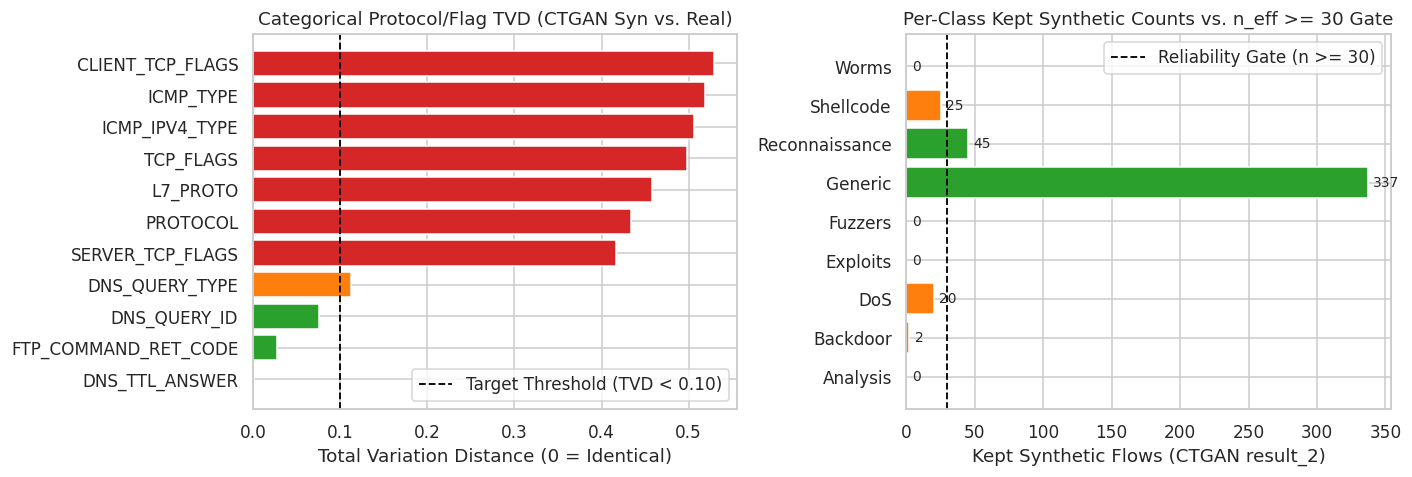

Mean Categorical TVD: 0.3254 | Classes passing n_eff >= 30: 2/9


In [5]:
# Metric 3: Categorical TVD + Effective Sample Gate (n_eff >= 30)
real_cat_pool = real_attacks[real_attacks["Attack"].isin(covered_classes)]
tvd_rows = []
for col in cat_cols:
    p_r = real_cat_pool[col].astype(str).value_counts(normalize=True)
    p_s = ctgan_syn[col].astype(str).value_counts(normalize=True)
    cats = p_r.index.union(p_s.index)
    p_r_al = p_r.reindex(cats, fill_value=0.0)
    p_s_al = p_s.reindex(cats, fill_value=0.0)
    tvd = 0.5 * float((p_r_al - p_s_al).abs().sum())
    tvd_rows.append({"feature": col, "tvd": tvd})

tvd_df = pd.DataFrame(tvd_rows).sort_values("tvd", ascending=False)

all_attack_classes = sorted(real_attacks["Attack"].unique())
syn_counts = ctgan_syn["Attack"].value_counts().reindex(all_attack_classes, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bar_cols = ["#2ca02c" if v < 0.1 else ("#ff7f0e" if v < 0.25 else "#d62728") for v in tvd_df["tvd"]]
axes[0].barh(tvd_df["feature"][::-1], tvd_df["tvd"][::-1], color=bar_cols[::-1])
axes[0].axvline(0.10, color="black", linestyle="--", lw=1.2, label="Target Threshold (TVD < 0.10)")
axes[0].set_title("Categorical Protocol/Flag TVD (CTGAN Syn vs. Real)")
axes[0].set_xlabel("Total Variation Distance (0 = Identical)")
axes[0].legend()

gate_cols = ["#2ca02c" if v >= 30 else ("#ff7f0e" if v > 0 else "#d62728") for v in syn_counts.values]
axes[1].barh(syn_counts.index, syn_counts.values, color=gate_cols)
axes[1].axvline(30, color="black", linestyle="--", lw=1.2, label="Reliability Gate (n >= 30)")
for i, v in enumerate(syn_counts.values):
    axes[1].text(v + 4, i, str(v), va="center", fontsize=9)
axes[1].set_title("Per-Class Kept Synthetic Counts vs. n_eff >= 30 Gate")
axes[1].set_xlabel("Kept Synthetic Flows (CTGAN result_2)")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"Mean Categorical TVD: {tvd_df['tvd'].mean():.4f} | Classes passing n_eff >= 30: {(syn_counts >= 30).sum()}/{len(all_attack_classes)}")

## 4. Distribution Fidelity — Pure Synthetic KS Statistic & Normalized Wasserstein Distance
**Reference:** Xu et al. (2019), *CTGAN*, NeurIPS 2019 (`10.48550/arXiv.1907.00503`); Qian et al. (2023), *Synthcity* (`10.48550/arXiv.2301.07573`).  
**Interpretation:** Evaluates marginal fidelity **directly on pure synthetic flows** (`ctgan_syn` vs. `real_attacks`, avoiding dilution from the 690,228 real rows). Plots the top divergent continuous features by KS statistic and Normalized Wasserstein Distance, alongside the ECDF of the most divergent feature.

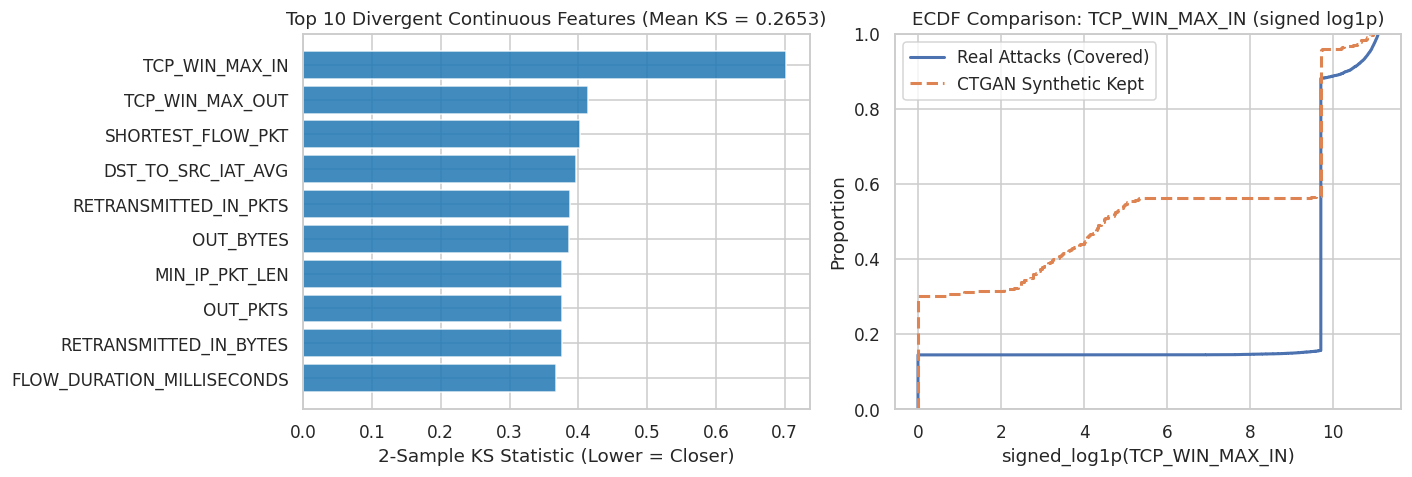

Pure Synthetic Mean KS: 0.2653 | Mean Normalized Wasserstein: 0.02187


In [6]:
# Metric 4: Pure Synthetic KS & Normalized Wasserstein Distance
real_fid, med_fid = clean_numeric(real_attacks[real_attacks["Attack"].isin(covered_classes)], cont_cols)
syn_fid, _ = clean_numeric(ctgan_syn, cont_cols, med_fid)

fid_rows = []
for col in cont_cols:
    vr, vs = real_fid[col].values, syn_fid[col].values
    ks_res = ks_2samp(vr, vs)
    rng_val = max(1e-6, float(np.ptp(vr)))
    w_norm = float(wasserstein_distance(vr, vs) / rng_val)
    fid_rows.append({"feature": col, "ks_stat": float(ks_res.statistic), "w_norm": w_norm})

fid_df = pd.DataFrame(fid_rows).sort_values("ks_stat", ascending=False)
top10_fid = fid_df.head(10)
worst_feat = fid_df.iloc[0]["feature"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(top10_fid["feature"][::-1], top10_fid["ks_stat"][::-1], color="#1f77b4", alpha=0.85)
axes[0].set_title(f"Top 10 Divergent Continuous Features (Mean KS = {fid_df['ks_stat'].mean():.4f})")
axes[0].set_xlabel("2-Sample KS Statistic (Lower = Closer)")

# Plot ECDF for worst feature (signed log1p scale for readability across heavy tails)
vr_log = np.sign(real_fid[worst_feat]) * np.log1p(np.abs(real_fid[worst_feat]))
vs_log = np.sign(syn_fid[worst_feat]) * np.log1p(np.abs(syn_fid[worst_feat]))
sns.ecdfplot(vr_log, ax=axes[1], label="Real Attacks (Covered)", lw=2)
sns.ecdfplot(vs_log, ax=axes[1], label="CTGAN Synthetic Kept", lw=2, linestyle="--")
axes[1].set_title(f"ECDF Comparison: {worst_feat} (signed log1p)")
axes[1].set_xlabel(f"signed_log1p({worst_feat})")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"Pure Synthetic Mean KS: {fid_df['ks_stat'].mean():.4f} | Mean Normalized Wasserstein: {fid_df['w_norm'].mean():.5f}")

## 5. Distribution Fidelity — Spearman Correlation Difference Norm ($\|C_{\text{real}} - C_{\text{syn}}\|_F$)
**Reference:** Xu et al. (2019), *CTGAN*, NeurIPS 2019 (`10.48550/arXiv.1907.00503`); Qian et al. (2023), *Synthcity*.  
**Interpretation:** Compares the pairwise Spearman rank-correlation structure across continuous NetFlow attributes between `real_attacks` and `ctgan_syn` via the Frobenius norm and Mean Absolute Correlation Error (MACE).

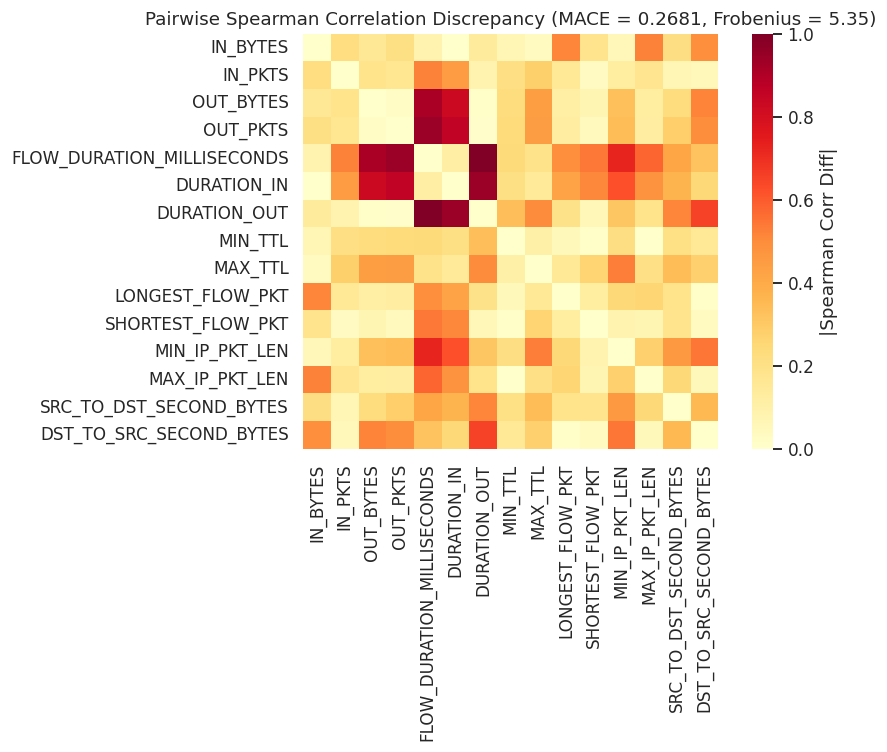

Mean Absolute Correlation Error (15 features): 0.2681 | Frobenius Norm: 5.3513


In [7]:
# Metric 5: Spearman Correlation Difference Norm
nonconst_cols = [c for c in cont_cols if real_fid[c].std() > 0 and syn_fid[c].std() > 0][:15]
corr_real = real_fid[nonconst_cols].corr(method="spearman").fillna(0.0)
corr_syn = syn_fid[nonconst_cols].corr(method="spearman").fillna(0.0)
corr_diff = (corr_real - corr_syn).abs()

frob_norm = float(np.linalg.norm((corr_real - corr_syn).values, ord="fro"))
mace = float(corr_diff.values.mean())

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_diff, cmap="YlOrRd", vmin=0.0, vmax=1.0, square=True, ax=ax, cbar_kws={"label": "|Spearman Corr Diff|"})
ax.set_title(f"Pairwise Spearman Correlation Discrepancy (MACE = {mace:.4f}, Frobenius = {frob_norm:.2f})")
plt.tight_layout()
plt.show()
print(f"Mean Absolute Correlation Error (15 features): {mace:.4f} | Frobenius Norm: {frob_norm:.4f}")

## 6. Distribution Fidelity & Coverage — Generative Precision & Recall ($k$-NN Manifold Support)
**Reference:** Sajjadi et al. (2018), *Assessing Generative Models via Precision and Recall*, NeurIPS 2018 (`10.48550/arXiv.1806.00035`); Alaa et al. (2022), *How Faithful is your Synthetic Data?*, ICML 2022 (`10.48550/arXiv.2102.08921`).  
**Interpretation:** Estimates real vs. synthetic manifold support using $k$-NN hypersphere radii ($k=5$) in standardized `signed_log1p` space: **Precision** = fraction of synthetic rows inside real support (realism); **Recall** = fraction of real rows inside synthetic support (diversity/mode coverage).

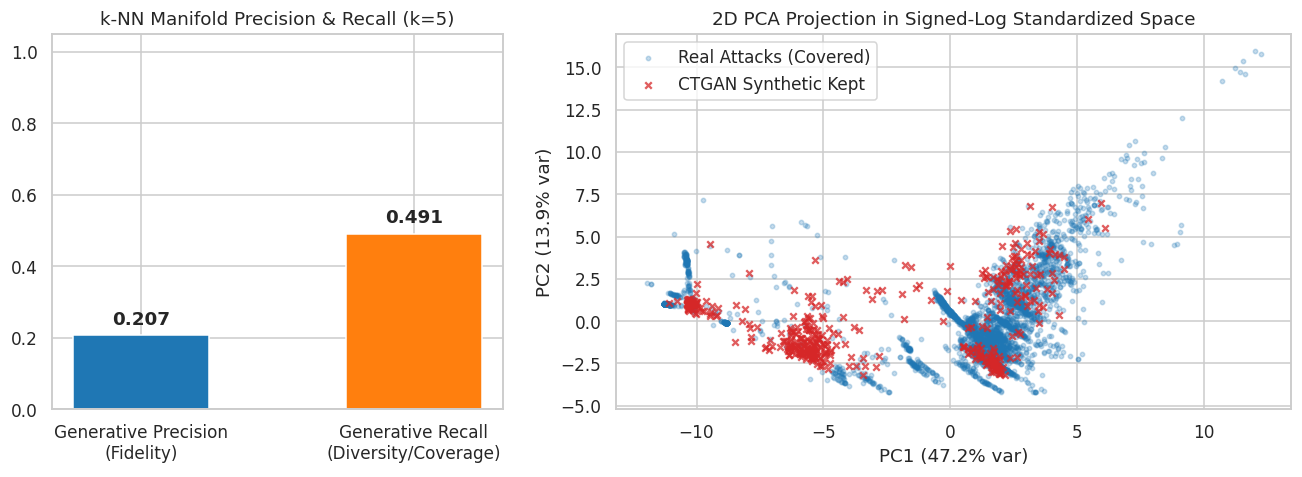

Generative Precision: 0.2075 | Generative Recall: 0.4910


In [8]:
# Metric 6: Generative Precision & Recall (k-NN Manifold Support, k=5)
def signed_log(X):
    return np.sign(X) * np.log1p(np.abs(X))

real_m_pool = real_attacks[real_attacks["Attack"].isin(covered_classes)].sample(n=4000, random_state=SEED)
Xr_raw, med_m = clean_numeric(real_m_pool, feature_cols)
Xs_raw, _ = clean_numeric(ctgan_syn, feature_cols, med_m)

scaler_m = StandardScaler().fit(signed_log(Xr_raw.values))
Er = scaler_m.transform(signed_log(Xr_raw.values))
Es = scaler_m.transform(signed_log(Xs_raw.values))

k_nn = 5
nn_r = NearestNeighbors(n_neighbors=k_nn + 1).fit(Er)
rad_r = nn_r.kneighbors(Er)[0][:, k_nn]
dist_s_to_r, idx_s_to_r = NearestNeighbors(n_neighbors=1).fit(Er).kneighbors(Es)
gen_precision = float((dist_s_to_r[:, 0] <= rad_r[idx_s_to_r[:, 0]]).mean())

nn_s = NearestNeighbors(n_neighbors=k_nn + 1).fit(Es)
rad_s = nn_s.kneighbors(Es)[0][:, k_nn]
dist_r_to_s, idx_r_to_s = NearestNeighbors(n_neighbors=1).fit(Es).kneighbors(Er)
gen_recall = float((dist_r_to_s[:, 0] <= rad_s[idx_r_to_s[:, 0]]).mean())

# 2D PCA visualization of manifold overlap
pca = PCA(n_components=2, random_state=SEED)
Zr = pca.fit_transform(Er)
Zs = pca.transform(Es)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].bar(["Generative Precision\n(Fidelity)", "Generative Recall\n(Diversity/Coverage)"], [gen_precision, gen_recall], color=["#1f77b4", "#ff7f0e"], width=0.5)
axes[0].set_ylim(0, 1.05)
axes[0].set_title("k-NN Manifold Precision & Recall (k=5)")
for i, v in enumerate([gen_precision, gen_recall]):
    axes[0].text(i, v + 0.03, f"{v:.3f}", ha="center", fontweight="bold")

axes[1].scatter(Zr[:, 0], Zr[:, 1], s=8, alpha=0.25, color="#1f77b4", label="Real Attacks (Covered)")
axes[1].scatter(Zs[:, 0], Zs[:, 1], s=18, alpha=0.75, color="#d62728", marker="x", label="CTGAN Synthetic Kept")
axes[1].set_title("2D PCA Projection in Signed-Log Standardized Space")
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} var)")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} var)")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"Generative Precision: {gen_precision:.4f} | Generative Recall: {gen_recall:.4f}")

## 7. Class Balance — Normalized Shannon Entropy ($H_{\text{norm}}$) & Deficit Fulfillment Ratio (DFR)
**Reference:** Shannon (1948), *A Mathematical Theory of Communication* (`10.1002/j.1538-7305.1948.tb01338.x`); Sarhan et al. (2020), *BDTA* (`10.1007/978-3-030-72802-1_9`).  
**Interpretation:** Left: Normalized multi-class Shannon entropy $H_{\text{norm}} \in [0, 1]$ across all 9 attack classes (`1.0` = perfectly uniform attack balance). Right: Per-class Deficit Fulfillment Ratio (`kept / target_deficit` from `dataset/synthetic_deficit.json`).

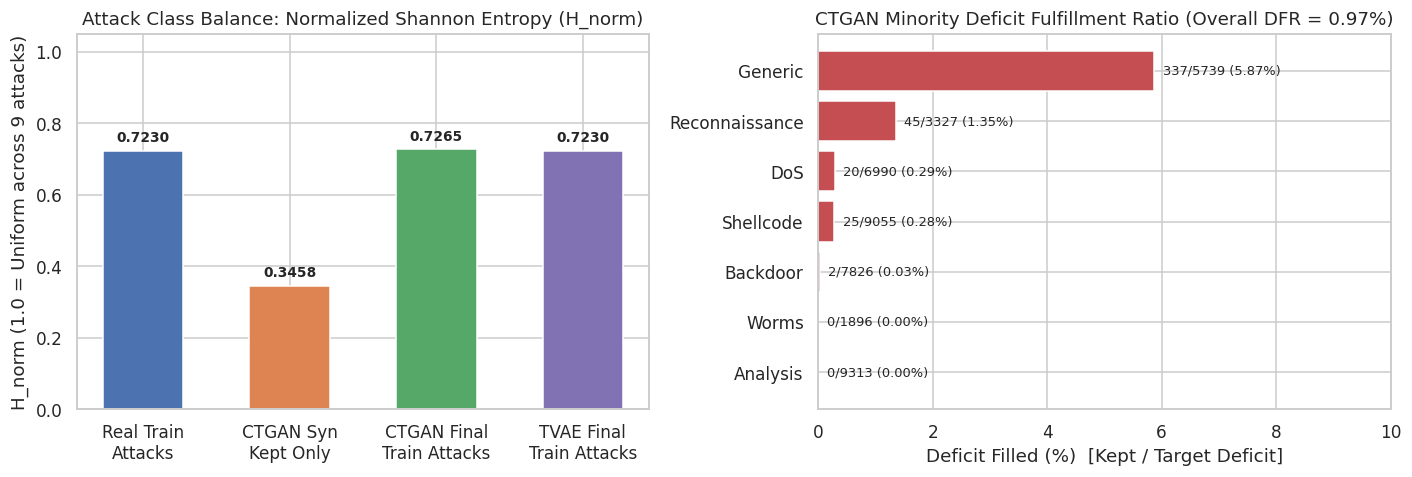

Class Coverage: 5/9 attack classes | Overall DFR: 0.9718%


In [9]:
# Metric 7: Normalized Class Shannon Entropy & Deficit Fulfillment Ratio (DFR)
def norm_shannon_entropy(series, classes):
    counts = series.value_counts().reindex(classes, fill_value=0).values.astype(float)
    total = counts.sum()
    if total == 0:
        return 0.0
    p = counts[counts > 0] / total
    return float(-np.sum(p * np.log(p)) / np.log(len(classes)))

atk_classes = sorted(deficit_cfg["synthetic_deficit"].keys())
h_real = norm_shannon_entropy(real_attacks["Attack"], atk_classes)
h_syn = norm_shannon_entropy(ctgan_syn["Attack"], atk_classes)
h_ctgan_final = norm_shannon_entropy(ctgan_final_train[ctgan_final_train["Label"] == 1]["Attack"], atk_classes)
h_tvae_final = norm_shannon_entropy(tvae_final_train[tvae_final_train["Label"] == 1]["Attack"], atk_classes)

deficits = pd.Series(deficit_cfg["synthetic_deficit"]).reindex(atk_classes).fillna(0)
kept_per_cls = ctgan_syn["Attack"].value_counts().reindex(atk_classes, fill_value=0)
dfr_per_cls = (kept_per_cls / deficits.replace(0, np.nan)).fillna(0.0)
overall_dfr = float(np.minimum(kept_per_cls, deficits).sum() / max(1, deficits.sum()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
labels_h = ["Real Train\nAttacks", "CTGAN Syn\nKept Only", "CTGAN Final\nTrain Attacks", "TVAE Final\nTrain Attacks"]
vals_h = [h_real, h_syn, h_ctgan_final, h_tvae_final]
axes[0].bar(labels_h, vals_h, color=["#4c72b0", "#dd8452", "#55a868", "#8172b3"], width=0.55)
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Attack Class Balance: Normalized Shannon Entropy (H_norm)")
axes[0].set_ylabel("H_norm (1.0 = Uniform across 9 attacks)")
for i, v in enumerate(vals_h):
    axes[0].text(i, v + 0.025, f"{v:.4f}", ha="center", fontsize=9, fontweight="bold")

dfr_plot = dfr_per_cls[deficits > 0].sort_values()
axes[1].barh(dfr_plot.index, dfr_plot.values * 100, color="#c44e52")
axes[1].set_title(f"CTGAN Minority Deficit Fulfillment Ratio (Overall DFR = {overall_dfr:.2%})")
axes[1].set_xlabel("Deficit Filled (%)  [Kept / Target Deficit]")
for i, (cls_name, v) in enumerate(dfr_plot.items()):
    axes[1].text(v * 100 + 0.15, i, f"{kept_per_cls[cls_name]}/{int(deficits[cls_name])} ({v:.2%})", va="center", fontsize=8.5)
axes[1].set_xlim(0, max(10.0, dfr_plot.max() * 100 + 3.0))
plt.tight_layout()
plt.show()
print(f"Class Coverage: {(kept_per_cls > 0).sum()}/9 attack classes | Overall DFR: {overall_dfr:.4%}")

## 8. Class Balance & Utility — TSTR, Augmentation Gain ($\Delta$ TR+S vs. TRTR) & Bootstrap 95% CI
**Reference:** Xu et al. (2019), *CTGAN*, NeurIPS 2019 (`10.48550/arXiv.1907.00503`); Efron (1979), *Bootstrap Methods* (`10.1214/aos/1176344552`); Wolf et al. (2026), CISIS 2026 (`10.1007/978-3-032-29251-3`).  
**Interpretation:** Trains `HistGradientBoostingClassifier` on Real Train (`TRTR`), Synthetic-Only (`TSTR`), and Real + CTGAN Synthetic (`TR+S`), evaluating Macro F1 and Rare-Attack F1 on `NF-UNSW-NB15-v3_test.csv` with 95% bootstrap confidence intervals ($B=200$ test resamples).

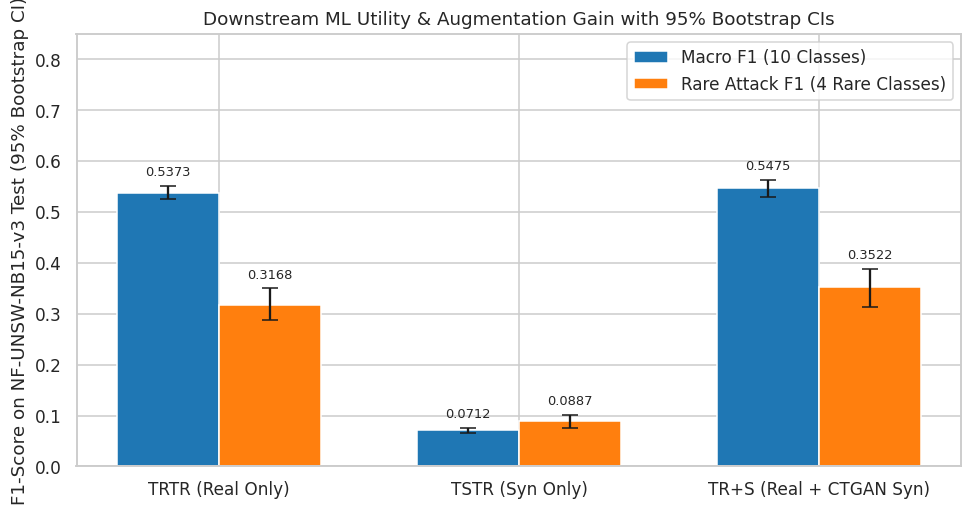

ML Efficacy Ratio (TSTR/TRTR): 0.1325
Augmentation Gain (TR+S - TRTR): Macro F1 = +0.0102 | Rare F1 = +0.0354


In [10]:
# Metric 8: TRTR vs TSTR vs TR+S with Bootstrap 95% CI
all_labels = sorted(train_df["Attack"].unique())
label_to_id = {l: i for i, l in enumerate(all_labels)}
rare_mask = np.isin(all_labels, RARE_CLASSES)

X_tr_u, med_u = clean_numeric(train_df, feature_cols)
y_tr_u = train_df["Attack"].map(label_to_id).values

X_te_u, _ = clean_numeric(test_df, feature_cols, med_u)
y_te_u = test_df["Attack"].map(label_to_id).values

X_syn_u, _ = clean_numeric(ctgan_syn, feature_cols, med_u)
y_syn_u = ctgan_syn["Attack"].map(label_to_id).values

def fit_eval_regime(X_train, y_train, name):
    sw = compute_sample_weight("balanced", y_train) ** 0.5
    clf = HistGradientBoostingClassifier(max_depth=8, max_iter=80, learning_rate=0.1, random_state=SEED)
    clf.fit(X_train, y_train, sample_weight=sw)
    preds = clf.predict(X_te_u)
    # Bootstrap 95% CI on test predictions
    macro_b, rare_b = [], []
    n_te = len(y_te_u)
    for _ in range(200):
        idx = rng.integers(0, n_te, size=n_te)
        f1_c = f1_score(y_te_u[idx], preds[idx], labels=np.arange(len(all_labels)), average=None, zero_division=0)
        macro_b.append(f1_c.mean())
        rare_b.append(f1_c[rare_mask].mean())
    f1_full = f1_score(y_te_u, preds, labels=np.arange(len(all_labels)), average=None, zero_division=0)
    return {
        "regime": name,
        "macro_f1": float(f1_full.mean()),
        "macro_lo": float(np.percentile(macro_b, 2.5)),
        "macro_hi": float(np.percentile(macro_b, 97.5)),
        "rare_f1": float(f1_full[rare_mask].mean()),
        "rare_lo": float(np.percentile(rare_b, 2.5)),
        "rare_hi": float(np.percentile(rare_b, 97.5)),
    }

res_trtr = fit_eval_regime(X_tr_u, y_tr_u, "TRTR (Real Only)")
res_tstr = fit_eval_regime(X_syn_u, y_syn_u, "TSTR (Syn Only)")
res_trs = fit_eval_regime(pd.concat([X_tr_u, X_syn_u], ignore_index=True), np.r_[y_tr_u, y_syn_u], "TR+S (Real + CTGAN Syn)")

util_df = pd.DataFrame([res_trtr, res_tstr, res_trs])
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(util_df))
w = 0.34
ax.bar(x - w/2, util_df["macro_f1"], w, yerr=[util_df["macro_f1"] - util_df["macro_lo"], util_df["macro_hi"] - util_df["macro_f1"]], capsize=5, label="Macro F1 (10 Classes)", color="#1f77b4")
ax.bar(x + w/2, util_df["rare_f1"], w, yerr=[util_df["rare_f1"] - util_df["rare_lo"], util_df["rare_hi"] - util_df["rare_f1"]], capsize=5, label="Rare Attack F1 (4 Rare Classes)", color="#ff7f0e")
ax.set_xticks(x)
ax.set_xticklabels(util_df["regime"])
ax.set_ylim(0, 0.85)
ax.set_ylabel("F1-Score on NF-UNSW-NB15-v3 Test (95% Bootstrap CI)")
ax.set_title("Downstream ML Utility & Augmentation Gain with 95% Bootstrap CIs")
for i, row in util_df.iterrows():
    ax.text(i - w/2, row["macro_hi"] + 0.02, f"{row['macro_f1']:.4f}", ha="center", fontsize=8.5)
    ax.text(i + w/2, row["rare_hi"] + 0.02, f"{row['rare_f1']:.4f}", ha="center", fontsize=8.5)
ax.legend()
plt.tight_layout()
plt.show()
print(f"ML Efficacy Ratio (TSTR/TRTR): {res_tstr['macro_f1']/res_trtr['macro_f1']:.4f}")
print(f"Augmentation Gain (TR+S - TRTR): Macro F1 = {res_trs['macro_f1']-res_trtr['macro_f1']:+.4f} | Rare F1 = {res_trs['rare_f1']-res_trtr['rare_f1']:+.4f}")

## 9. Security & Protocol Validity — NetFlow Cross-Feature Invariant Rate (PFIR) & Boundary Adherence
**Reference:** Ring et al. (2019), *Computers & Security* (`10.1016/j.cose.2018.12.012`); Yin et al. (2022), *NetShare*, ACM SIGCOMM (`10.1145/3544216.3544251`); Patki et al. (2016), *SDV* (`10.1109/DSAA.2016.49`).  
**Interpretation:** Audits `ctgan_syn` against concrete RFC/NetFlow cross-feature invariants (`MIN_TTL <= MAX_TTL`, `SHORTEST_FLOW_PKT <= LONGEST_FLOW_PKT <= MAX_IP_PKT_LEN`, `IN_BYTES >= IN_PKTS`, `TCP_FLAGS == 0` for UDP, `ICMP_TYPE == 0` for TCP/UDP, and `BoundaryAdherence` inside real `[min, max]`).

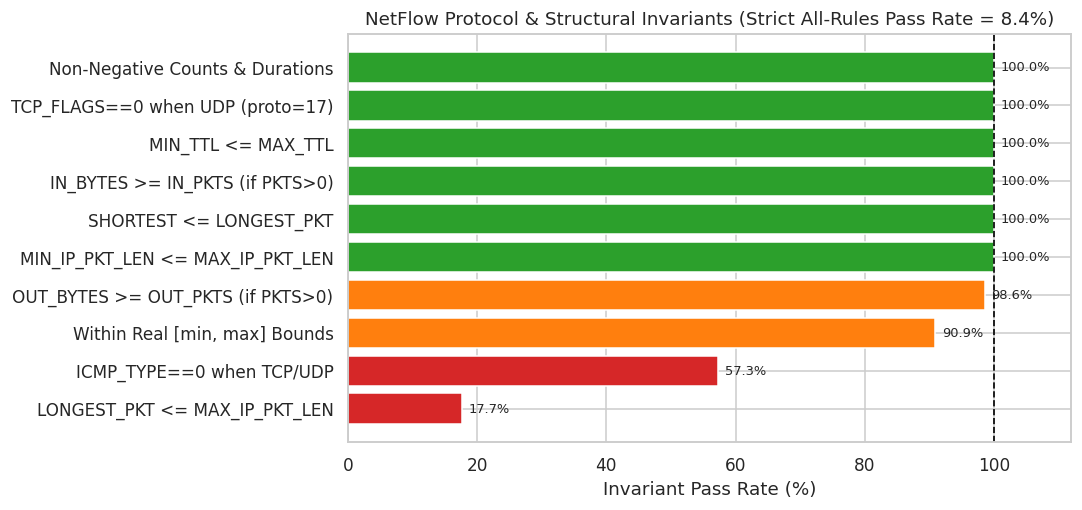

Strict All-Invariants Pass Rate (PFIR): 8.39% (36/429 rows)


In [11]:
# Metric 9: NetFlow Protocol Invariant Rate (PFIR) & Boundary Adherence
s = ctgan_syn.copy()
r_num, _ = clean_numeric(real_attacks, feature_cols)
s_num, _ = clean_numeric(s, feature_cols)

invariants = {
    "MIN_TTL <= MAX_TTL": (s["MIN_TTL"] <= s["MAX_TTL"]),
    "SHORTEST <= LONGEST_PKT": (s["SHORTEST_FLOW_PKT"] <= s["LONGEST_FLOW_PKT"]),
    "LONGEST_PKT <= MAX_IP_PKT_LEN": (s["LONGEST_FLOW_PKT"] <= s["MAX_IP_PKT_LEN"]),
    "MIN_IP_PKT_LEN <= MAX_IP_PKT_LEN": (s["MIN_IP_PKT_LEN"] <= s["MAX_IP_PKT_LEN"]),
    "IN_BYTES >= IN_PKTS (if PKTS>0)": ((s["IN_PKTS"] == 0) | (s["IN_BYTES"] >= s["IN_PKTS"])),
    "OUT_BYTES >= OUT_PKTS (if PKTS>0)": ((s["OUT_PKTS"] == 0) | (s["OUT_BYTES"] >= s["OUT_PKTS"])),
    "TCP_FLAGS==0 when UDP (proto=17)": ((s["PROTOCOL"] != 17) | (s["TCP_FLAGS"] == 0)),
    "ICMP_TYPE==0 when TCP/UDP": ((~s["PROTOCOL"].isin([6, 17])) | (s["ICMP_TYPE"] == 0)),
    "Non-Negative Counts & Durations": ((s_num >= 0).all(axis=1)),
    "Within Real [min, max] Bounds": (((s_num >= r_num.min()) & (s_num <= r_num.max())).all(axis=1)),
}

inv_rates = {k: float(v.mean()) for k, v in invariants.items()}
all_valid_mask = np.ones(len(s), dtype=bool)
for mask in invariants.values():
    all_valid_mask &= mask.values
pfir_overall = float(all_valid_mask.mean())

inv_ser = pd.Series(inv_rates).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.8))
bar_c = ["#2ca02c" if v == 1.0 else ("#ff7f0e" if v >= 0.8 else "#d62728") for v in inv_ser.values]
ax.barh(inv_ser.index, inv_ser.values * 100, color=bar_c)
ax.axvline(100.0, color="black", linestyle="--", lw=1.1)
for i, v in enumerate(inv_ser.values):
    ax.text(min(v * 100 + 1.0, 101.5), i, f"{v:.1%}", va="center", fontsize=8.5)
ax.set_xlim(0, 112)
ax.set_xlabel("Invariant Pass Rate (%)")
ax.set_title(f"NetFlow Protocol & Structural Invariants (Strict All-Rules Pass Rate = {pfir_overall:.1%})")
plt.tight_layout()
plt.show()
print(f"Strict All-Invariants Pass Rate (PFIR): {pfir_overall:.2%} ({all_valid_mask.sum()}/{len(s)} rows)")

## 10. NetFlow Security Structure — L2 Directional Asymmetry JSD & L3 TCP-Flag Entropy
**Reference:** Ring et al. (2019), *Computers & Security* (`10.1016/j.cose.2018.12.012`); Yin et al. (2022), *NetShare* (`10.1145/3544216.3544251`); Shannon (1948) (`10.1002/j.1538-7305.1948.tb01338.x`).  
**Interpretation:** Left: L2 directional asymmetry ratio `IN_BYTES / (IN_BYTES + OUT_BYTES)` comparing unidirectional vs. bidirectional session structure via Jensen-Shannon Divergence (JSD). Right: L3 Shannon entropy across `TCP_FLAGS`, `CLIENT_TCP_FLAGS`, and `SERVER_TCP_FLAGS`.

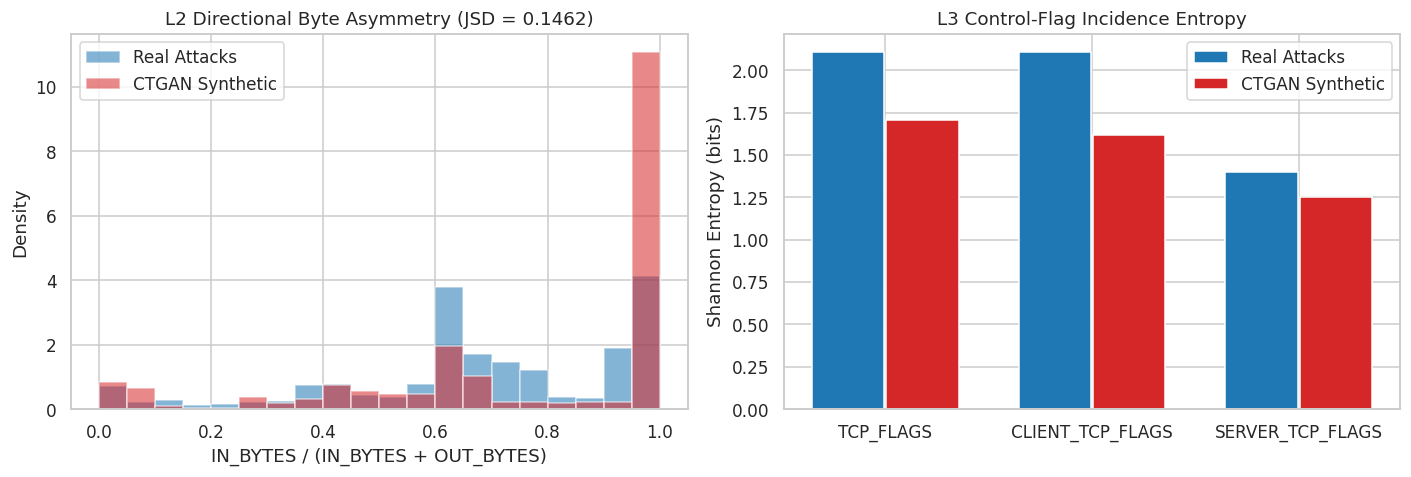

L2 Directional Asymmetry JSD: 0.1462 | L3 Mean Flag Entropy Diff: 0.3450 bits


In [12]:
# Metric 10: L2 Directional Asymmetry JSD & L3 TCP-Flag Entropy
real_l = real_attacks[real_attacks["Attack"].isin(covered_classes)]
eps = 1e-9
asym_real = (real_l["IN_BYTES"] / (real_l["IN_BYTES"] + real_l["OUT_BYTES"] + eps)).clip(0, 1)
asym_syn = (ctgan_syn["IN_BYTES"] / (ctgan_syn["IN_BYTES"] + ctgan_syn["OUT_BYTES"] + eps)).clip(0, 1)

bins = np.linspace(0, 1, 21)
p_r, _ = np.histogram(asym_real, bins=bins, density=False)
p_s, _ = np.histogram(asym_syn, bins=bins, density=False)
l2_jsd = float(jensenshannon(p_r / max(1, p_r.sum()), p_s / max(1, p_s.sum()), base=2) ** 2)

def shannon_entropy_bits(s):
    p = s.value_counts(normalize=True).values
    return float(-np.sum(p * np.log2(p + 1e-12)))

flag_cols = ["TCP_FLAGS", "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS"]
ent_real = [shannon_entropy_bits(real_l[c]) for c in flag_cols]
ent_syn = [shannon_entropy_bits(ctgan_syn[c]) for c in flag_cols]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(asym_real, bins=bins, density=True, alpha=0.55, label="Real Attacks", color="#1f77b4")
axes[0].hist(asym_syn, bins=bins, density=True, alpha=0.55, label="CTGAN Synthetic", color="#d62728")
axes[0].set_title(f"L2 Directional Byte Asymmetry (JSD = {l2_jsd:.4f})")
axes[0].set_xlabel("IN_BYTES / (IN_BYTES + OUT_BYTES)")
axes[0].set_ylabel("Density")
axes[0].legend()

x_f = np.arange(len(flag_cols))
axes[1].bar(x_f - 0.18, ent_real, 0.35, label="Real Attacks", color="#1f77b4")
axes[1].bar(x_f + 0.18, ent_syn, 0.35, label="CTGAN Synthetic", color="#d62728")
axes[1].set_xticks(x_f)
axes[1].set_xticklabels(flag_cols)
axes[1].set_ylabel("Shannon Entropy (bits)")
axes[1].set_title("L3 Control-Flag Incidence Entropy")
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"L2 Directional Asymmetry JSD: {l2_jsd:.4f} | L3 Mean Flag Entropy Diff: {np.mean(np.abs(np.array(ent_real)-np.array(ent_syn))):.4f} bits")

## 11. Privacy & Novelty — Distance to Closest Record (DCR), Exact Copy & Mode-Collapse Rate
**Reference:** Qian et al. (2023), *Synthcity* (`10.48550/arXiv.2301.07573`); Alaa et al. (2022), *ICML* (`10.48550/arXiv.2102.08921`); Patki et al. (2016), *SDV* (`NewRowSynthesis`, `10.1109/DSAA.2016.49`).  
**Interpretation:** Computes 1-NN Euclidean distance in signed-log standardized space from `ctgan_syn` to `real_train` (`d_train`) vs. `holdout_df` (`d_holdout`), along with `NewRowSynthesis` (`1 - ExactCopyRate`) and `IntraSynDupRate` (duplicate rows within `ctgan_syn`).

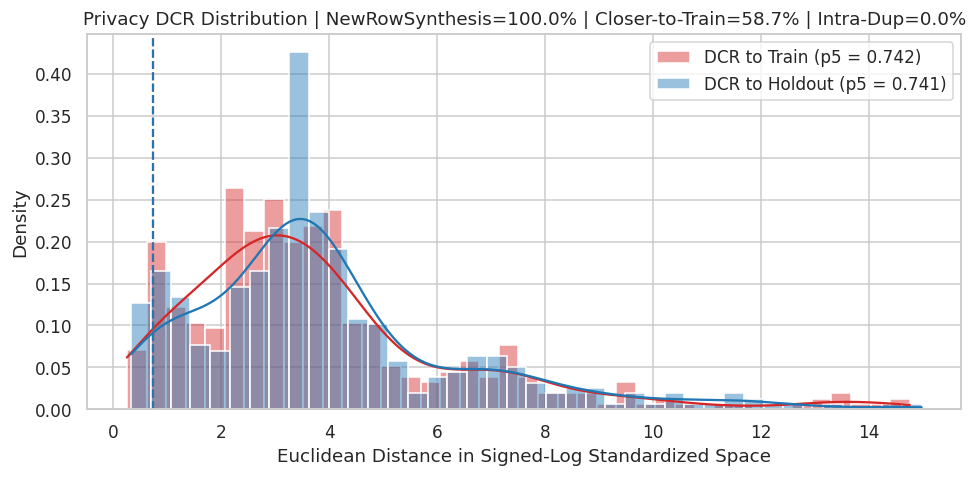

Exact Copy Rate: 0.00% | NewRowSynthesis: 100.00% | Closer-to-Train: 58.74% | Intra-Syn Dup: 0.00%


In [13]:
# Metric 11: DCR (Size-Matched Real Attacks vs Holdout Attacks), NewRowSynthesis, and Intra-Synthetic Duplication
n_ref = len(holdout_attacks)
tr_sub = real_attacks.sample(n=n_ref, random_state=SEED)
ho_sub = holdout_attacks.copy()

Xtr_p, med_p = clean_numeric(tr_sub, feature_cols)
Xho_p, _ = clean_numeric(ho_sub, feature_cols, med_p)
Xsy_p, _ = clean_numeric(ctgan_syn, feature_cols, med_p)

sc_p = StandardScaler().fit(signed_log(Xtr_p.values))
E_tr = sc_p.transform(signed_log(Xtr_p.values))
E_ho = sc_p.transform(signed_log(Xho_p.values))
E_sy = sc_p.transform(signed_log(Xsy_p.values))

d_tr = NearestNeighbors(n_neighbors=1).fit(E_tr).kneighbors(E_sy)[0][:, 0]
d_ho = NearestNeighbors(n_neighbors=1).fit(E_ho).kneighbors(E_sy)[0][:, 0]

exact_copy_rate = float((d_tr < 1e-9).mean())
new_row_synthesis = 1.0 - exact_copy_rate
closer_to_train = float((d_tr < d_ho).mean())
intra_dup_rate = float(ctgan_syn.duplicated(subset=feature_cols).mean())

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(d_tr, bins=40, kde=True, stat="density", alpha=0.45, color="#d62728", label=f"DCR to Train (p5 = {np.percentile(d_tr, 5):.3f})", ax=ax)
sns.histplot(d_ho, bins=40, kde=True, stat="density", alpha=0.45, color="#1f77b4", label=f"DCR to Holdout (p5 = {np.percentile(d_ho, 5):.3f})", ax=ax)
ax.axvline(np.percentile(d_tr, 5), color="#d62728", linestyle="--", lw=1.4)
ax.axvline(np.percentile(d_ho, 5), color="#1f77b4", linestyle="--", lw=1.4)
ax.set_title(f"Privacy DCR Distribution | NewRowSynthesis={new_row_synthesis:.1%} | Closer-to-Train={closer_to_train:.1%} | Intra-Dup={intra_dup_rate:.1%}")
ax.set_xlabel("Euclidean Distance in Signed-Log Standardized Space")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Exact Copy Rate: {exact_copy_rate:.2%} | NewRowSynthesis: {new_row_synthesis:.2%} | Closer-to-Train: {closer_to_train:.2%} | Intra-Syn Dup: {intra_dup_rate:.2%}")

## 12. Downstream Two-Tier IDS Security & Balance — CTGAN (`result_2`) vs. TVAE (`result_1`)
**Reference:** Sarhan et al. (2020), *BDTA* (`10.1007/978-3-030-72802-1_9`); Chicco & Jurman (2020), *BMC Genomics* (`10.1186/s12864-019-6413-7`).  
**Interpretation:** Compares the latest end-to-end Two-Tier IDS metrics across Validation, Test, and Holdout splits from `pipeline_tuning_summary.json`.

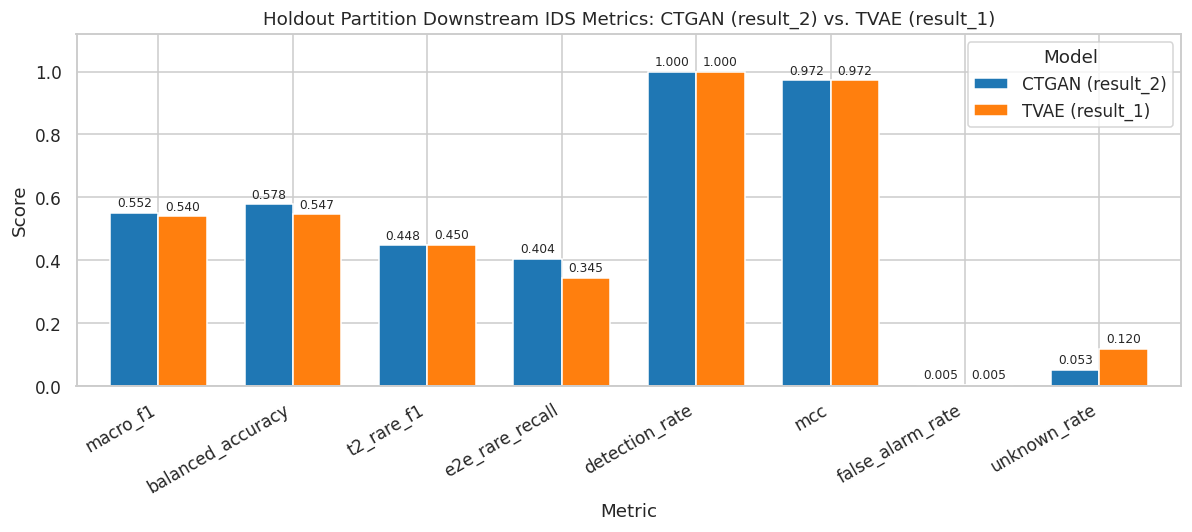

Model,CTGAN (result_2),TVAE (result_1)
Metric,,
macro_f1,0.5520,0.5404
balanced_accuracy,0.5783,0.5468
t2_rare_f1,0.4483,0.4501
e2e_rare_recall,0.4044,0.3453
detection_rate,1.0000,1.0000
mcc,0.9723,0.9722
false_alarm_rate,0.0046,0.0046
unknown_rate,0.0527,0.1196


In [14]:
# Metric 12: Downstream IDS Security & Balance Summary (CTGAN result_2 vs TVAE result_1)
metrics_keys = ["macro_f1", "balanced_accuracy", "t2_rare_f1", "e2e_rare_recall", "detection_rate", "mcc", "false_alarm_rate", "unknown_rate"]
splits = [("validation_performance", "Val"), ("test_performance", "Test"), ("holdout_performance", "Holdout")]

rows_ids = []
for model_name, summ in [("CTGAN (result_2)", ctgan_summary), ("TVAE (result_1)", tvae_summary)]:
    for sp_key, sp_lbl in splits:
        sp = summ.get(sp_key, {})
        for mk in metrics_keys:
            rows_ids.append({"Model": model_name, "Split": sp_lbl, "Metric": mk, "Value": sp.get(mk, np.nan)})

ids_df = pd.DataFrame(rows_ids)
holdout_cmp = ids_df[ids_df["Split"] == "Holdout"].pivot(index="Metric", columns="Model", values="Value").loc[metrics_keys]

fig, ax = plt.subplots(figsize=(11, 5))
holdout_cmp.plot(kind="bar", ax=ax, color=["#1f77b4", "#ff7f0e"], width=0.72)
ax.set_title("Holdout Partition Downstream IDS Metrics: CTGAN (result_2) vs. TVAE (result_1)")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout()
plt.show()
display(holdout_cmp.round(4))